# Block Y1B: Creative Brief Template

Please, use this template to write down your solutions to the DataLab Tasks. If you have any questions, please, contact your mentor or the content responsible. 

## Important Notes:
- [ ] Please, rename the file to ```CreativeBrief_<your_name>_<studentnumber>.ipynb``` before submitting it. 
- [ ] Upload this template to the 'Deliverables' folder in your BUas GitHub repository.
- [ ] You are allowed to add as many (Markdown/Python) cells as you need. 
- [ ] If the task requires you to only write code or text, please, delete the unnecessary cell.
- [ ] Your work should be reproducible, meaning that we should be able to run your code in the template and get the same results as you did. Tip: use relative paths to load your data!
- [ ] Ensure that before you hand in the template, you press ```Restart & Run all```; we should be able to see the results of your code in the notebook (i.e., output cells).
- [ ] Ensure that your code in the template is ```error-free```. In other words, we should not see any error messages when we run your code.

## Project Overview
This project focuses on the analysis of diabetes patient data in order to apply in machine learning algorithms. <br>
It will involve the students working on a wide variety of machine learning techniques, ranging from basic data analysis to the optimisation of advanced models. 


## Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
...

Ellipsis

## *Task 1: Exploratory Data Analysis (EDA) with Python and SQL
_________


### **Task 1A: Exploratory Data Analysis with SQL**

### Task Description
Etablish a connection between Python and a database with performing basic operations using SQL and perform exploratory data analysis with sql to understand the dataset's characteristics, patterns.

### Task 1A.1: General Overview of the Data

In [3]:
# Count the total number of records in the encounter table
SELECT COUNT(*) AS total_records
FROM encounter;

# Check the distribution of different admission types

SELECT admission_type_id , COUNT(*) AS count, 
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM encounter), 2) AS percentage
FROM encounter
GROUP BY admission_type_id
ORDER BY count DESC;


   
  
# Explore the top discharge dispositions

SELECT discharge_disposition_id, COUNT(*) AS total
FROM encounter
GROUP BY discharge_disposition_id 
ORDER BY total DESC
LIMIT 10;


SyntaxError: Invalid star expression (4201194750.py, line 2)

### Task 1A.2: Identifying Missing or Anomalous Data

In [ ]:
#Check for missing values in the race column (Hint: Count the occurance of each unique value in this column)

select count(*) as countperrace
from patient 
group by race 
WITH rollup  ;

#Check for missing or unusual values in the weight column

SELECT 
    COUNT(*) AS total_missing_weight
FROM 
    patient 
WHERE 
    weight IS NULL;

### Task 1A.3: Understanding Age Distribution

In [ ]:
# Explore the age distribution of the patients
SELECT age, COUNT(*) AS count_per_age
FROM patient 
GROUP BY age
ORDER BY 
    age;

### Task 1A.4: Admission Trends by Source and Type

In [ ]:
# Analyze how different admission sources contribute to hospital admissions 
# (Hint: Calculate the number of admissions per source)
SELECT 
    admission_source_id , 
    COUNT(*) AS total_admissions
FROM 
    admission_source
GROUP BY 
    admission_source_id 
ORDER BY 
    total_admissions DESC;
#Investigate which admission types correspond to specific admission sources
# (Hint: add admission type to your previous query)

SELECT 
    admission_source_id , 
    admission_type_id, 
    COUNT(*) AS total_admissions
FROM 
    admission_source,
    admission_type
GROUP BY 
    admission_source_id , 
    admission_type_id;

### Task 1A.5: Hospital Stay and Readmission Patterns

In [ ]:
# Find the average time in hospital for each admission type
    select 
	at2.description as admission_type,
	AVG(e.time_in_hospital) as avg_time_in_hospital 
from encounter e 
join public.admission_type at2 
	on e.admission_type_id = at2.admission_type_id 
group by at2.description 
order by avg_time_in_hospital desc;

#Investigate readmission rates by admission type

SELECT 
    admission_type_id , 
    COUNT(*) AS total_admissions,
    SUM(CASE WHEN readmitted = 'Yes' THEN 1 ELSE 0 END) AS total_readmissions,
    ROUND(SUM(CASE WHEN readmitted = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS readmission_rate
FROM 
    encounter
GROUP BY 
    admission_type_id 
ORDER BY 
    readmission_rate DESC;

### Task 1A.6: Comparing Admission Types and Outcomes

In [ ]:
# Compare discharge dispositions across different admission types
SELECT 
    admission_type_id , 
    discharge_disposition_id , 
    COUNT(*) AS count_per_disposition
FROM 
    admission_type,
    discharge_disposition
GROUP BY 
    admission_type_id , 
    discharge_disposition_id;

# Compare readmission rates by discharge disposition
    SELECT 
    dd.description AS discharge_disposition,
    AVG(CASE WHEN e.readmitted = 'Yes' THEN 1 ELSE 0 END) AS readmission_rate
FROM encounter e
JOIN public.discharge_disposition dd 
    ON e.discharge_disposition_id = dd.discharge_disposition_id
GROUP BY dd.description
ORDER BY readmission_rate DESC;


+++++
### **Task 1B: Exploratory Data Analysis with Python**

### Task Description
Perform comprehensive exploratory data analysis to understand the dataset's characteristics, patterns, and potential challenges. <br>
It is crucial to understand the structure and quality of the dataset before diving into any analysis or modeling.

### 1B.1: Loading the data:

In [ ]:
import pandas as pd 
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
df = pd.read_csv(file_path)
#display first few rows
print(df.head(10))

   encounter_id  patient_nbr             race  gender       age weight  \
0       2278392      8222157        Caucasian  Female    [0-10)      ?   
1        149190     55629189        Caucasian  Female   [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female   [20-30)      ?   
3        500364     82442376        Caucasian    Male   [30-40)      ?   
4         16680     42519267        Caucasian    Male   [40-50)      ?   
5         35754     82637451        Caucasian    Male   [50-60)      ?   
6         55842     84259809        Caucasian    Male   [60-70)      ?   
7         63768    114882984        Caucasian    Male   [70-80)      ?   
8         12522     48330783        Caucasian  Female   [80-90)      ?   
9         15738     63555939        Caucasian  Female  [90-100)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                       

### 1B.2: Analysing the dataset shape:

In [14]:
# Dataset shape
print(df.shape)
# Column names
columns = df.columns
print(columns)

(101766, 50)
Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')


### 1B.3: Load and Explore a Dataset Using NumPy

In [ ]:
import numpy as np

# Load the dataset
data = np.genfromtxt(file_path,delimiter=',',skip_header=1)

# Check the shape of the dataset
print("Dataset shape:",data.shape)

# Preview the first few rows
print("First 5 rows of the dataset:\n",)
print(data[:5])

Dataset shape: (101766, 50)
First 5 rows of the dataset:

[[2.2783920e+06 8.2221570e+06           nan           nan           nan
            nan 6.0000000e+00 2.5000000e+01 1.0000000e+00 1.0000000e+00
            nan           nan 4.1000000e+01 0.0000000e+00 1.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 2.5083000e+02           nan
            nan 1.0000000e+00           nan           nan           nan
            nan           nan           nan           nan           nan
            nan           nan           nan           nan           nan
            nan           nan           nan           nan           nan
            nan           nan           nan           nan           nan
            nan           nan           nan           nan           nan]
 [1.4919000e+05 5.5629189e+07           nan           nan           nan
            nan 1.0000000e+00 1.0000000e+00 7.0000000e+00 3.0000000e+00
            nan           nan 5.9000000e+01 0.0000000e+00 1.8000000e+01
  0.0

### 1B.4: Analysing data types:

In [ ]:
# Data types
import pandas as pd
file_path =r"C:\Users\Asus\Desktop\diabetic_data.csv"
df = pd.read_csv(file_path)
data_type = df.dtypes
print("Data Type:\n" , data_type)

# Unique values in categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns
unique_values = {col: df[col].unique() for col in categorical_columns}

print("Unique values in categorical columns:")
for col, values in unique_values.items():
    print(f"\ncolumn: {col}")
    print(values)


Data Type:
 encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepir

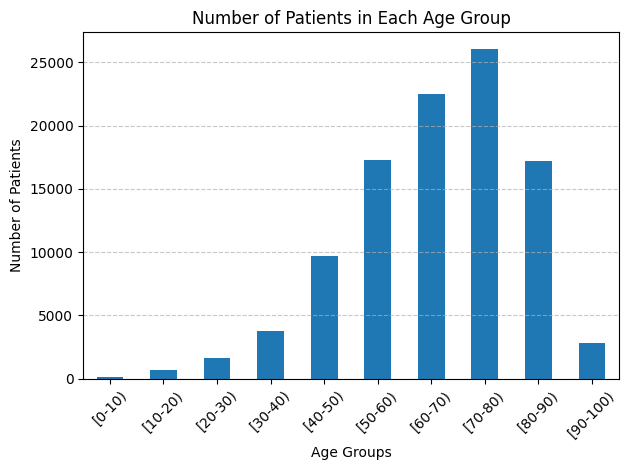

In [17]:
#Number of patients in each group
import pandas as pd
import matplotlib.pyplot as plt 

age_group_counts = df['age'].value_counts().sort_index()

age_group_counts.plot(kind='bar',title='Number of Patients in Each Age Group')

# Add labels and improve layout
plt.xlabel('Age Groups')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

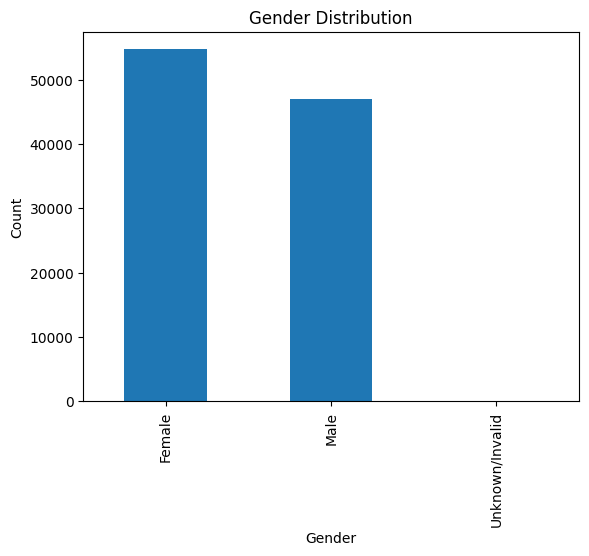

In [ ]:
gender_counts = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['gender'].value_counts()

gender_counts.plot(kind='bar', title='Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()


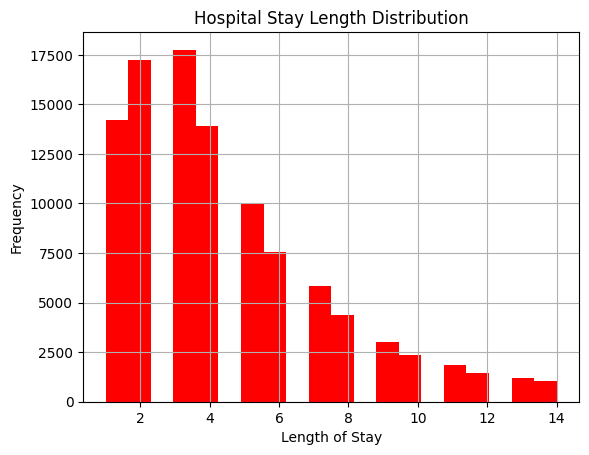

In [22]:
#Create a histogram to show the frequency of different lengths of stay in the hospital
pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['time_in_hospital'].hist(bins=20, color='red')
plt.title('Hospital Stay Length Distribution')
plt.xlabel('Length of Stay')
plt.ylabel('Frequency')
plt.show()



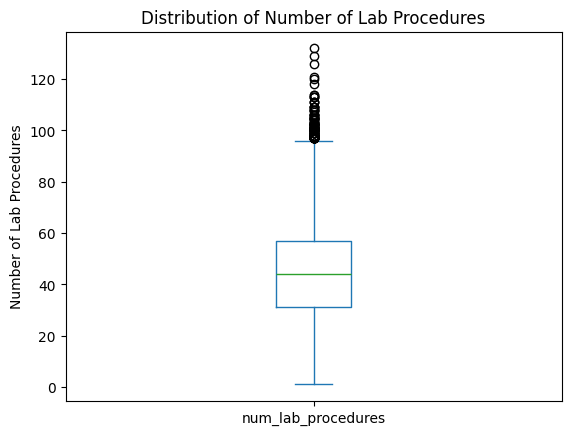

In [24]:
#Use a box plot to show the distribution of num_lab_procedures
pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")['num_lab_procedures'].plot(kind='box')
plt.title('Distribution of Number of Lab Procedures')
plt.ylabel('Number of Lab Procedures')
plt.show()


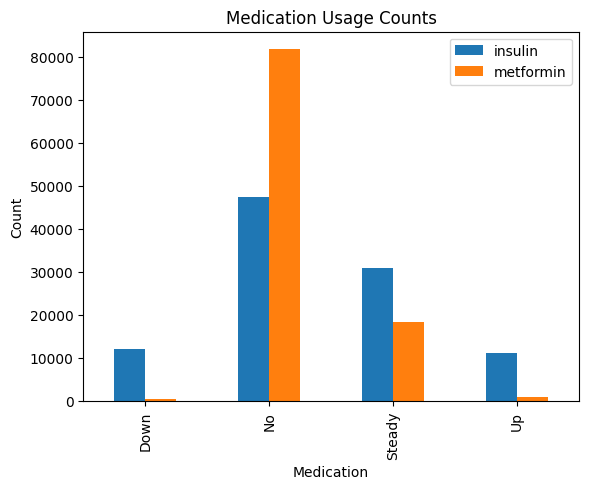

In [10]:
#Create a bar chart showing the counts of "Yes", "No", or "Steady" values for key medications like insulin, metformin, etc
df[['insulin', 'metformin']].apply(pd.Series.value_counts).plot(kind='bar')

# Add labels and title
plt.title('Medication Usage Counts')
plt.xlabel('Medication')
plt.ylabel('Count')
plt.show()

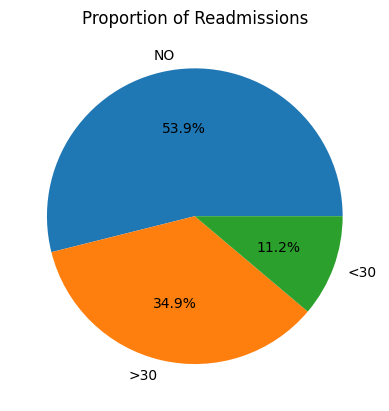

In [32]:
#Create a pie chart showing the proportions of patients readmitted within 30 days (<30), after 30 days (>30), or not at all (NO)
# Load dataset
df = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")

# Count occurrences of readmission categories
readmission_counts = df['readmitted'].value_counts()

# Plot pie chart
readmission_counts.plot(kind='pie', autopct='%1.1f%%', title='Proportion of Readmissions')
plt.ylabel('')  # Hide the default ylabel
plt.show()

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


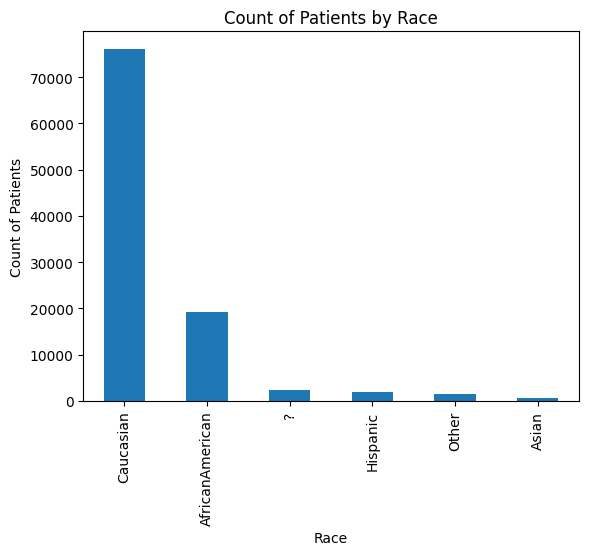

In [35]:
#Create a bar chart showing the count of patients by race
# Count occurrences of each race
race_counts = df['race'].value_counts()
print(race_counts)

# Plot bar chart
race_counts.plot(kind='bar',  title='Count of Patients by Race')
plt.xlabel('Race')
plt.ylabel('Count of Patients')
plt.show()

                    A1Cresult                                        ...  \
admission_source_id        1   2   3    4   5    6     7  8   9  10  ...   
race                                                                 ...   
?                         140   0   0   32   0   67   166  0  12  1  ...   
AfricanAmerican           601  30   6   57  18  163  2548  1   4  0  ...   
Asian                      33   0   0    0   1    0    99  0   0  0  ...   
Caucasian                3042  35  27  339  47  295  7957  2   7  6  ...   
Hispanic                   89   3   0    6   1    0   365  1   0  0  ...   
Other                      67   3   0    4   0    0   223  0   0  0  ...   

                    weight                                    
admission_source_id     8   9  10 11 13 14    17   20  22 25  
race                                                          
?                        0  71  1  0  0  0    83    1   0  0  
AfricanAmerican          3  22  0  1  0  2   580    3   1  0  


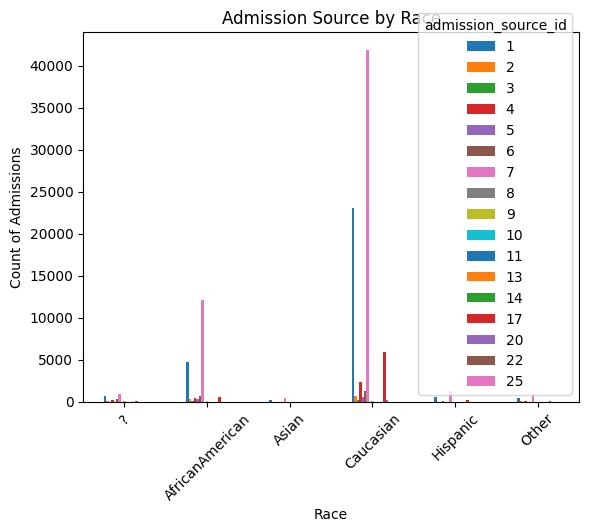

In [49]:
#Create a bar chart showing the count of patients by race
# Load dataset
df = pd.read_csv(r"C:\Users\Asus\Desktop\diabetic_data.csv")

# Create a pivot table to count admission sources by race

print(pd.pivot_table(df, index='race', columns='admission_source_id', aggfunc='count', fill_value=0))


# Plot stacked bar chart
race_admission_counts = pd.crosstab(df['race'], df['admission_source_id'])
race_admission_counts.plot(kind='bar', title='Admission Source by Race')
plt.xlabel('Race')
plt.ylabel('Count of Admissions')
plt.xticks(rotation=45)
plt.show()

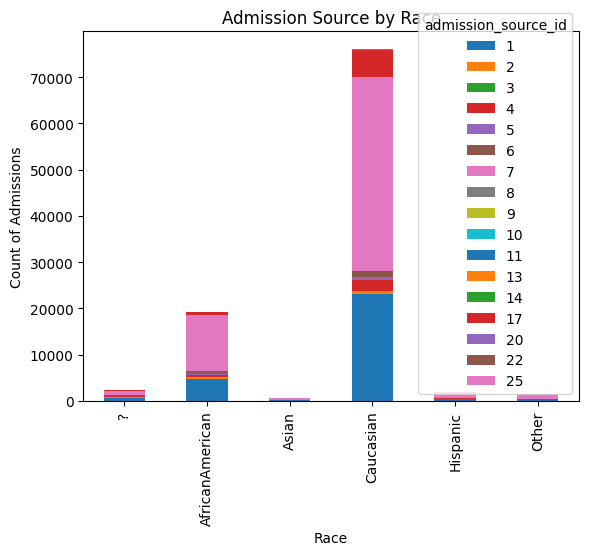

In [50]:
#Use a stacked bar chart to see which admission_source_id is common for each race


# Create a pivot table to count admission sources by race
race_admission_counts = pd.crosstab(df['race'], df['admission_source_id'])

# Plot stacked bar chart
race_admission_counts.plot(kind='bar', stacked=True, title='Admission Source by Race')
plt.xlabel('Race')
plt.ylabel('Count of Admissions')
plt.show()


medical_specialty
?                         49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
                          ...  
Proctology                    1
Speech                        1
SportsMedicine                1
Perinatology                  1
Neurophysiology               1
Name: count, Length: 73, dtype: int64


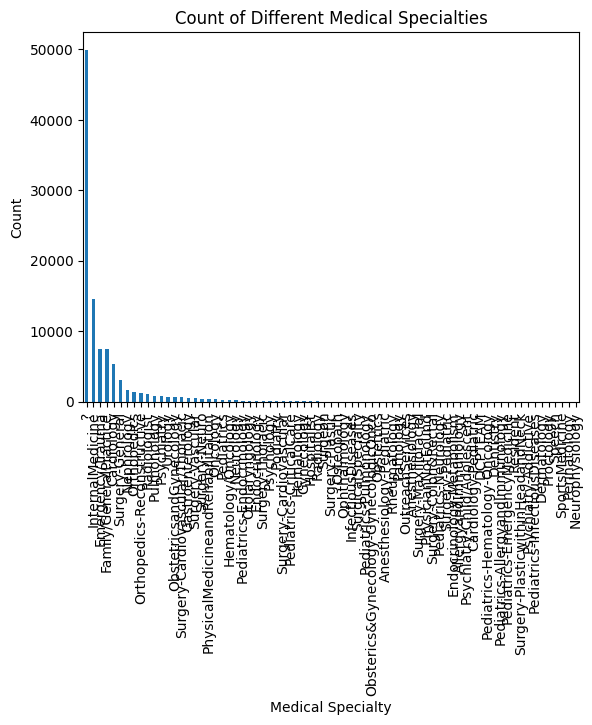

In [52]:
#Use a bar chart to show the counts of different medical_specialty values
# Count occurrences of each medical_specialty
specialty_counts = df['medical_specialty'].value_counts()
print(specialty_counts)

# Plot bar chart
specialty_counts.plot(kind='bar', title='Count of Different Medical Specialties')
plt.xlabel('Medical Specialty')
plt.ylabel('Count')
plt.show()

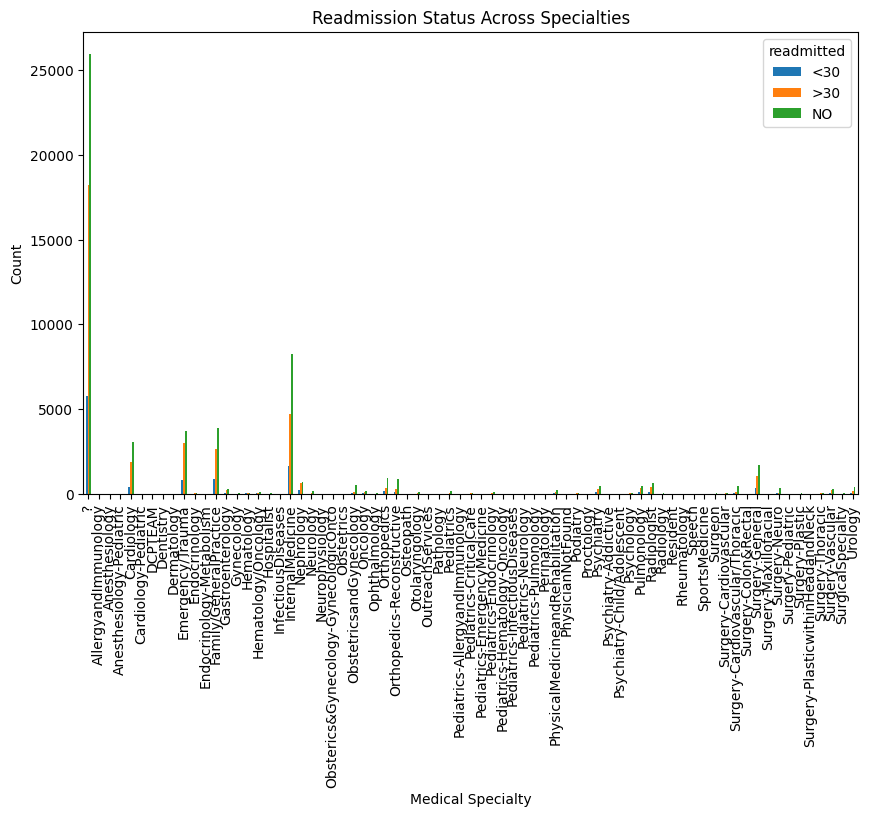

In [53]:
#Use a grouped bar chart to show readmitted status across specialties
# Group by medical_specialty and readmitted, then count occurrences
readmission_counts = df.groupby(['medical_specialty', 'readmitted']).size().unstack()

# Plot grouped bar chart
readmission_counts.plot(kind='bar', stacked=False, figsize=(10, 6))

# Add labels and title
plt.title('Readmission Status Across Specialties')
plt.xlabel('Medical Specialty')
plt.ylabel('Count')
plt.show()

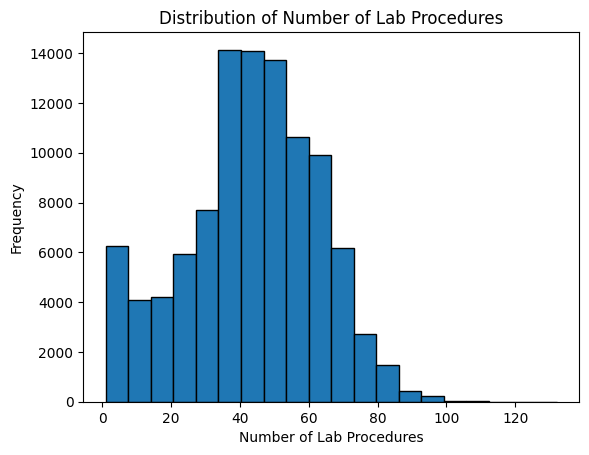

In [56]:
#visualise distribution of a numeric column

# Plot histogram to visualize the distribution of 'num_lab_procedures'
df['num_lab_procedures'].plot(kind='hist', bins=20,edgecolor='black')

# Add title and labels
plt.title('Distribution of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.ylabel('Frequency')
plt.show()

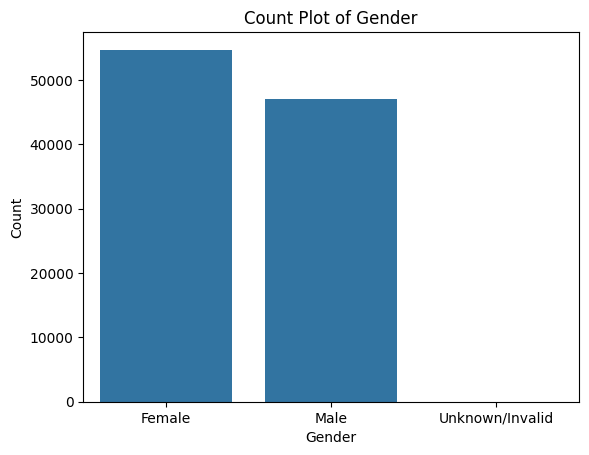

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#Perform count plot of a categorical variable

#Plot count plot for a categorical variable (e.g., 'gender')
sns.countplot(x='gender', data=df)

# Add title and labels
plt.title('Count Plot of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### 1B.5: Exploratory Data Analysis (EDA) with Visualisations

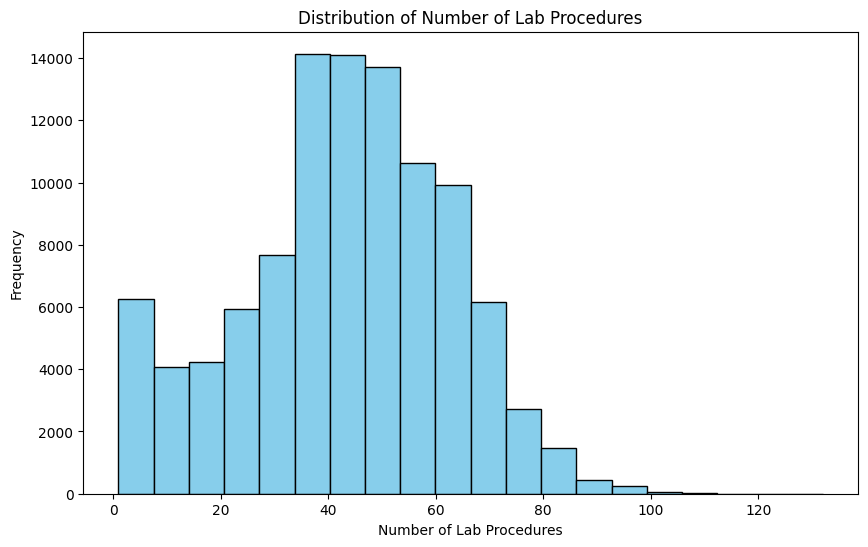

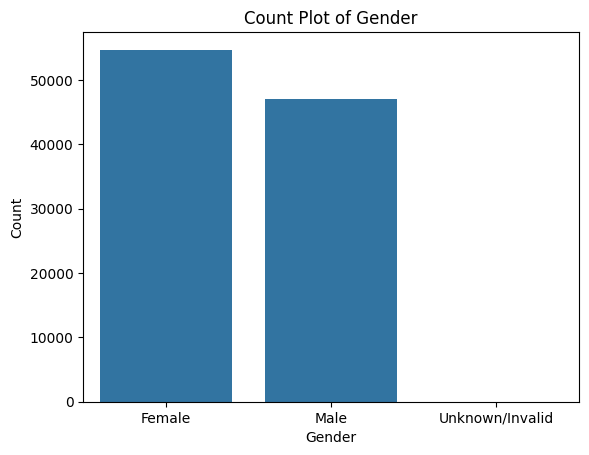

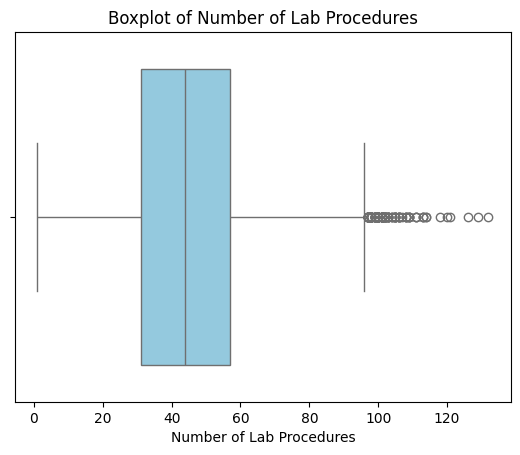

In [ ]:
import matplotlib
import seaborn 

# Distribution of a numeric column
# Plot histogram to visualize the distribution of 'num_lab_procedures'
df['num_lab_procedures'].plot(kind='hist', bins=20, color='skyblue', edgecolor='black', figsize=(10, 6))

# Add title and labels
plt.title('Distribution of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.ylabel('Frequency')
plt.show()

# Count plot of a categorical variable

# Plot count plot for a categorical variable (e.g., 'gender')
sns.countplot(x='gender', data=df)

# Add title and labels
plt.title('Count Plot of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Boxplot to detect outliers

# Create boxplot to detect outliers in 'num_lab_procedures'
sns.boxplot(x=df['num_lab_procedures'], color='skyblue')

# Add title and labels
plt.title('Boxplot of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.show()

_________
## *Task 2: Data Processing
### Task Description
Create a robust data preprocessing pipeline to handle missing values, encode categorical variables, and scale numerical features.

### **Task 2.1: Initial Cleaning and Pre-processing**

#### 2.1.1: Load and Visualise the Data
- Use pandas to load the dataset.
- Visualise the first few rows to understand the structure of the data.

   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No

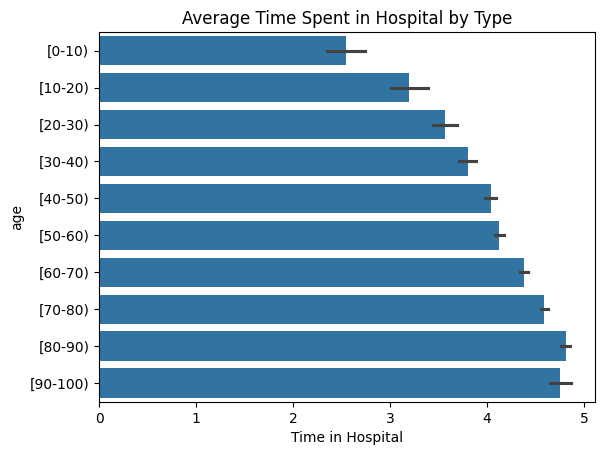

In [59]:
# Importing required Python libraries
import pandas as pd
import numpy as ns
import seaborn as sns
import matplotlib.pyplot as plt

# Loading the data
path=r"C:\Users\Asus\Desktop\diabetic_data.csv"

file=pd.read_csv(path)

# visualise the first few rows of the data
print(file.head())
  #<add your code here>
sns.barplot(data= file , x = 'time_in_hospital',y='age')
plt.xlabel("Time in Hospital")
plt.ylabel("age")
plt.title("Average Time Spent in Hospital by Type")
plt.show()

#### 2.1.2: Display Data Types and Check for Incorrect Types

- Use the .dtypes attribute to display each column's data type.
- Identify columns that have unexpected data types (e.g., numeric data stored as strings).

In [60]:
# Display data types of each column
print(file.dtypes)

# for column in file.select_dtypes(include=['object']).columns:
#     print(column)



encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

#### 2.1.3: Identify and Remove Duplicate Rows

- Check for duplicate rows.
- If duplicates exist, remove them 

In [64]:
for i in file.duplicated():
    count=0
    if i==True:
        count+=1




print(f"Number of duplicate rows: {count}")

# Drop duplicates if any
x=file.drop_duplicates()
print(x)


Number of duplicate rows: 0
        encounter_id  patient_nbr             race  gender      age weight  \
0            2278392      8222157        Caucasian  Female   [0-10)      ?   
1             149190     55629189        Caucasian  Female  [10-20)      ?   
2              64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3             500364     82442376        Caucasian    Male  [30-40)      ?   
4              16680     42519267        Caucasian    Male  [40-50)      ?   
...              ...          ...              ...     ...      ...    ...   
101761     443847548    100162476  AfricanAmerican    Male  [70-80)      ?   
101762     443847782     74694222  AfricanAmerican  Female  [80-90)      ?   
101763     443854148     41088789        Caucasian    Male  [70-80)      ?   
101764     443857166     31693671        Caucasian  Female  [80-90)      ?   
101765     443867222    175429310        Caucasian    Male  [70-80)      ?   

        admission_type_id  discharg

### Task 2.2: Handling Metadata and Missing Values
#### 2.2.1: Identify Metadata from the Dataset
Metadata includes information like column names, data types, and any additional descriptive information.

In [65]:
# Display metadata including column names and data types
print(file.describe())

       encounter_id   patient_nbr  admission_type_id  \
count  1.017660e+05  1.017660e+05      101766.000000   
mean   1.652016e+08  5.433040e+07           2.024006   
std    1.026403e+08  3.869636e+07           1.445403   
min    1.252200e+04  1.350000e+02           1.000000   
25%    8.496119e+07  2.341322e+07           1.000000   
50%    1.523890e+08  4.550514e+07           1.000000   
75%    2.302709e+08  8.754595e+07           3.000000   
max    4.438672e+08  1.895026e+08           8.000000   

       discharge_disposition_id  admission_source_id  time_in_hospital  \
count             101766.000000        101766.000000     101766.000000   
mean                   3.715642             5.754437          4.395987   
std                    5.280166             4.064081          2.985108   
min                    1.000000             1.000000          1.000000   
25%                    1.000000             1.000000          2.000000   
50%                    1.000000             7.00000


#### 2.2.2: Analyse Different Types of Data
- Categorize columns based on their data types (e.g., numerical, categorical).
- Describe the significance of each data type and how it might impact data processing.

In [66]:
# Describe data to understand different types
numerical_columns=file.select_dtypes(include=['int64','float64']).columns.tolist
categorial_columns=file.select_dtypes(include=['object']).columns.tolist
print(numerical_columns)
print(categorial_columns)


<bound method IndexOpsMixin.tolist of Index(['encounter_id', 'patient_nbr', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses'],
      dtype='object')>
<bound method IndexOpsMixin.tolist of Index(['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed',

#### 2.2.3: Identify Missing Values
- Missing values can significantly impact model performance and analysis.
- Count missing values in each column.
- Calculate the percentage of missing values.

In [67]:
# Identify and calculate the percentage of missing values
missing=file.isnull().sum()
print(missing)
rows=file.shape[0]
percentage=(missing/rows)*100
print(percentage)
print("Missing values (in percentage) for each column:\n",  )

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

#### 2.2.4: Splitting Data for Analysis
Splitting data ensures that models are trained on one portion of the data and tested on another, unseen portion.

In [68]:
from sklearn.model_selection import train_test_split


# Features and target
X = file.drop(columns=['time_in_hospital'])
y = file['time_in_hospital']

# Split dataset
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.5,random_state=42)

___________
## *Task 3: Machine Learning
### Task Description
Implement various machine learning algorithms for regression, classification and clustering and evaluating them.

### **Task 3.1: Implementing Regression Baseline**
#### 3.1.1: Loading the data
- Use pandas to load the dataset.

In [70]:
import pandas as pd
from pandas.plotting import scatter_matrix
# Reload the dataset as a Pandas DataFrame
file_path = r"C:\Users\Asus\Desktop\diabetic_data.csv"
data = pd.read_csv(file_path)
data.head(10)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [71]:
data['admission_type_id'].value_counts()

admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64

In [82]:
data['admission_type_id'].replace(5,8)
data['admission_type_id'].replace(6,8)
data['admission_type_id'].value_counts()

from sklearn.preprocessing import OneHotEncoder
import numpy as np
model=OneHotEncoder()
f = model.fit_transform(np.array(data['patient_nbr']).reshape(-1,1))
model.categories_
# column_name=['Emergency','Urgent','Elective','NewBorn','TraumaCenter','Not mapped']
# f_dense=f.toarray()
# data[column_name]=pd.DataFrame(f_dense,index=data.index)




[array([      135,       378,       729, ..., 189445127, 189481478,
        189502619])]

In [ ]:
data['weight'].value_counts()
# because the huge number of weight is unknown I will delete this column
data=data.drop('weight',axis=1)
# envounter id it was just ID for each patient since it wasn't important I delete this too
data=data.drop('encounter_id',axis=1)

In [21]:
# Loop through all columns and print unique values
for col in data.columns:
    print(f"Unique values in '{col}':")
    print(data[col].unique())
    print()


Unique values in 'patient_nbr':
[  8222157  55629189  86047875 ... 140199494 120975314 175429310]

Unique values in 'race':
['Caucasian' 'AfricanAmerican' '?' 'Other' 'Asian' 'Hispanic']

Unique values in 'gender':
['Female' 'Male' 'Unknown/Invalid']

Unique values in 'age':
['[0-10)' '[10-20)' '[20-30)' '[30-40)' '[40-50)' '[50-60)' '[60-70)'
 '[70-80)' '[80-90)' '[90-100)']

Unique values in 'admission_type_id':
[6 1 2 3 4 5 8 7]

Unique values in 'discharge_disposition_id':
[25  1  3  6  2  5 11  7 10  4 14 18  8 13 12 16 17 22 23  9 20 15 24 28
 19 27]

Unique values in 'admission_source_id':
[ 1  7  2  4  5  6 20  3 17  8  9 14 10 22 11 25 13]

Unique values in 'time_in_hospital':
[ 1  3  2  4  5 13 12  9  7 10  6 11  8 14]

Unique values in 'payer_code':
['?' 'MC' 'MD' 'HM' 'UN' 'BC' 'SP' 'CP' 'SI' 'DM' 'CM' 'CH' 'PO' 'WC' 'OT'
 'OG' 'MP' 'FR']

Unique values in 'medical_specialty':
['Pediatrics-Endocrinology' '?' 'InternalMedicine'
 'Family/GeneralPractice' 'Cardiology' 'Surgery

In [25]:
data['metformin-pioglitazone']=data['metformin-pioglitazone'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['metformin-rosiglitazone']=data['metformin-rosiglitazone'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['glimepiride-pioglitazone']=data['glimepiride-pioglitazone'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['glipizide-metformin']=data['glipizide-metformin'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['troglitazone']=data['troglitazone'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['tolbutamide']=data['tolbutamide'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['acetohexamide']=data['acetohexamide'].str.lower().map({'no':0,'steady':1}).fillna(0)
data['diabetesMed']=data['diabetesMed'].str.lower().map({'no':0,'yes':1}).fillna(0)
for col in data.columns:
    print(f"Unique values in '{col}':")
    print(data[col].unique())
    print()

Unique values in 'patient_nbr':
[  8222157  55629189  86047875 ... 140199494 120975314 175429310]

Unique values in 'race':
['Caucasian' 'AfricanAmerican' '?' 'Other' 'Asian' 'Hispanic']

Unique values in 'gender':
['Female' 'Male' 'Unknown/Invalid']

Unique values in 'age':
['[0-10)' '[10-20)' '[20-30)' '[30-40)' '[40-50)' '[50-60)' '[60-70)'
 '[70-80)' '[80-90)' '[90-100)']

Unique values in 'admission_type_id':
[6 1 2 3 4 5 8 7]

Unique values in 'discharge_disposition_id':
[25  1  3  6  2  5 11  7 10  4 14 18  8 13 12 16 17 22 23  9 20 15 24 28
 19 27]

Unique values in 'admission_source_id':
[ 1  7  2  4  5  6 20  3 17  8  9 14 10 22 11 25 13]

Unique values in 'time_in_hospital':
[ 1  3  2  4  5 13 12  9  7 10  6 11  8 14]

Unique values in 'payer_code':
['?' 'MC' 'MD' 'HM' 'UN' 'BC' 'SP' 'CP' 'SI' 'DM' 'CM' 'CH' 'PO' 'WC' 'OT'
 'OG' 'MP' 'FR']

Unique values in 'medical_specialty':
['Pediatrics-Endocrinology' '?' 'InternalMedicine'
 'Family/GeneralPractice' 'Cardiology' 'Surgery

In [26]:
# finding useless columns
for col in data.columns:
    if data[col].nunique()==1:
        print ([col])

# since in these two column it was just no I delete these two columns
data=data.drop(['examide','citoglipton'],axis=1)
data.columns

['examide']
['citoglipton']


Index(['patient_nbr', 'race', 'gender', 'age', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'payer_code', 'medical_specialty', 'num_lab_procedures',
       'num_procedures', 'num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3',
       'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

Index(['race', 'gender', 'age', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'payer_code', 'medical_specialty', 'num_lab_procedures',
       'num_procedures', 'num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3',
       'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

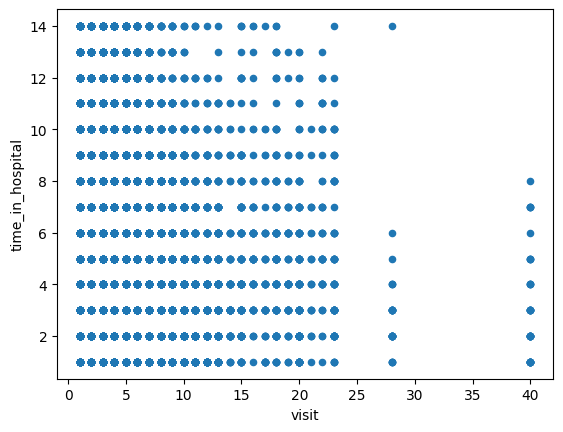

In [41]:
# Patient_num column
# data['patient_nbr'].value_counts()
data['visit']=data.groupby('patient_nbr')['patient_nbr'].transform('count')
data['visit'].describe()
data.plot.scatter(x='visit',y='time_in_hospital')
# as we can we can see there is no difference between a person who come for the first time or more 
# the person who comes for the first time could stay one day to 14 days 
# and the patient who comes 20 times could stay 1 day to 13 days then there is no coeffiecient on it so we can delete this column.
data=data.drop(['visit','patient_nbr'],axis=1)
data.columns

In [49]:
# race column
data['race'].unique()

array(['Caucasian', 'AfricanAmerican', '?', 'Other', 'Asian', 'Hispanic'],
      dtype=object)

In [53]:
data['race'].replace('?','Other',inplace=True)
data['race'].unique()

array(['Caucasian', 'AfricanAmerican', 'Other', 'Asian', 'Hispanic'],
      dtype=object)

In [42]:
# Selecting numerical features and target
numerical_features = data.select_dtypes(include=['number'])
corr_matrix= numerical_features.corr()  # Compute correlations
corr_matrix['time_in_hospital'].sort_values(ascending=False)
# print(corr_matrix)



time_in_hospital            1.000000
num_medications             0.466135
num_lab_procedures          0.318450
number_diagnoses            0.220186
num_procedures              0.191472
discharge_disposition_id    0.162748
number_inpatient            0.073623
diabetesMed                 0.062520
acetohexamide               0.010085
troglitazone                0.003524
tolbutamide                 0.003042
metformin-pioglitazone      0.001684
metformin-rosiglitazone    -0.000588
glipizide-metformin        -0.000626
glimepiride-pioglitazone   -0.002516
admission_source_id        -0.006965
number_outpatient          -0.008916
number_emergency           -0.009681
admission_type_id          -0.012500
Name: time_in_hospital, dtype: float64

array([[<Axes: xlabel='num_medications', ylabel='num_medications'>,
        <Axes: xlabel='num_lab_procedures', ylabel='num_medications'>,
        <Axes: xlabel='number_diagnoses', ylabel='num_medications'>,
        <Axes: xlabel='time_in_hospital', ylabel='num_medications'>],
       [<Axes: xlabel='num_medications', ylabel='num_lab_procedures'>,
        <Axes: xlabel='num_lab_procedures', ylabel='num_lab_procedures'>,
        <Axes: xlabel='number_diagnoses', ylabel='num_lab_procedures'>,
        <Axes: xlabel='time_in_hospital', ylabel='num_lab_procedures'>],
       [<Axes: xlabel='num_medications', ylabel='number_diagnoses'>,
        <Axes: xlabel='num_lab_procedures', ylabel='number_diagnoses'>,
        <Axes: xlabel='number_diagnoses', ylabel='number_diagnoses'>,
        <Axes: xlabel='time_in_hospital', ylabel='number_diagnoses'>],
       [<Axes: xlabel='num_medications', ylabel='time_in_hospital'>,
        <Axes: xlabel='num_lab_procedures', ylabel='time_in_hospital'>,
        <

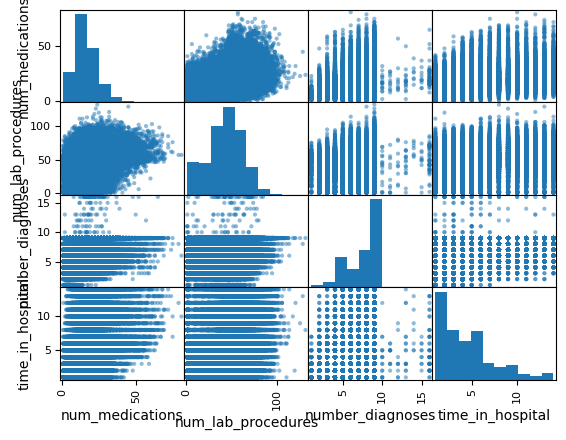

In [29]:
s=['num_medications','num_lab_procedures','number_diagnoses','time_in_hospital']
scatter_matrix(data[s])

#### 3.1.2: Start to implement Linear Regression as a baseline model

In [19]:
# importing requires sklearn packages for implementing linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
import pandas as pd
# ordinal_encoder=OrdinalEncoder()
# Defining features (X) and target (y)
x = data[['number_diagnoses','num_medications','num_lab_procedures']]
y = data['time_in_hospital'] #it should be numerical

#handling missing value
x = x.fillna('unknown')
y = y.fillna(y.mean()) #replacing missing value with mean

# Encoding categorical variables 
encoder = OneHotEncoder(drop='first')
x_encoded = encoder.fit_transform(x)
# x_ord = ordinal_encoder.fit_transform(x)
# x_ord.categories_

# Spliting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x_encoded,y,test_size=0.5,random_state=42)

# Initialising and training Linear Regression model
linear_model = LinearRegression()
linear_model.fit(x_train,y_train)


# Predictions
y_pred = linear_model.predict(x_test)

# Evaluation
mae =mean_absolute_error(y_test ,y_pred)

mse = mean_squared_error(y_pred, y_test) 

print(f'Linear Regression MAE: {mae}')
print(f'Linear Regression MSE: {mse}')


Linear Regression MAE: 1.9280138737357966
Linear Regression MSE: 6.42645123549233


##### You could try other linear models as well, such as Ridge, Lasso, useful information can be found [here](https://scikit-learn.org/stable/modules/linear_model.html#linear-model).

#### 3.1.3: Visualise the output for linear regression

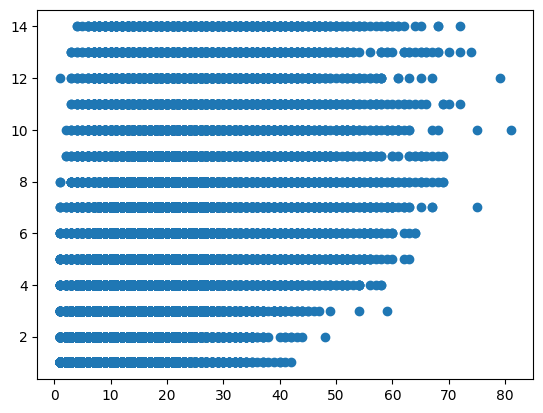

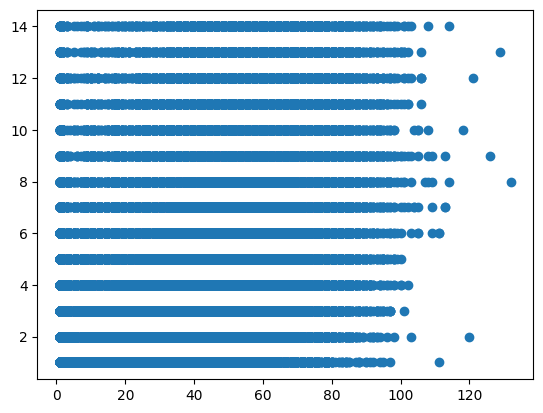

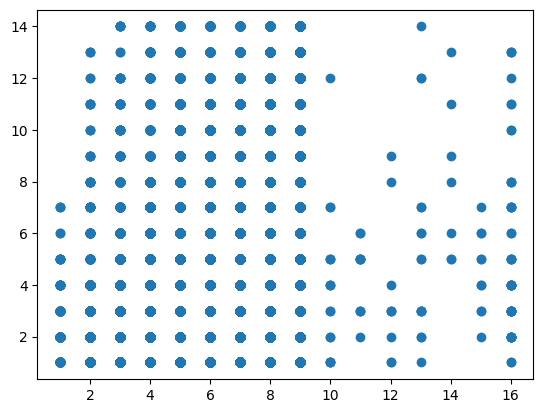

In [14]:
import matplotlib.pyplot as plt
x.shape[1]
s=['num_medications','num_lab_procedures','number_diagnoses']
for i in range(x.shape[1]):
    plt.scatter(x[s[i]],y)
    plt.show()
    plt.close()

#### 3.1.4: Implement Decision Tree Regression for Non-linear Relationships

In [28]:
# importing requires sklearn packages for implementing regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)


# Initialising and training Decision Tree Regressor
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(x_train, y_train)


# Predictions
y_pred_tree = tree_model.predict(x_test)

# Evaluation

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)

print(f"Decision Tree Regression MAE: {mae_tree}")
print(f"Decision Tree Regression MSE: {mse_tree}")

Decision Tree Regression MAE: 2.0972999962659102
Decision Tree Regression MSE: 7.828499761537474


#### 3.1.5: Implement Gradient Boosting Regression

In [16]:
# importing requires sklearn packages for implementing Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Initialising and training Gradient Boosting Regressor
gboost_model = GradientBoostingRegressor(random_state=42)
gboost_model.fit(x_train, y_train)

# Predictions
y_pred_gboost = gboost_model.predict(x_test)

# Evaluation
mae_gboost = mean_absolute_error(y_test,y_pred_gboost)
mse_gboost = mean_squared_error(y_test,y_pred_gboost)

print(f"Gradient Boosting Regression MAE: {mae_gboost}")
print(f"Gradient Boosting Regression MSE: {mse_gboost}")

Gradient Boosting Regression MAE: 1.8941274271499298
Gradient Boosting Regression MSE: 6.206846658732571


#### 3.1.6: Implement XGBoost Regression

In [17]:
# importing requires packages
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Initialize and train XGBoost Regressor
xgboost_model = xgb.XGBRegressor(random_state=42)
xgboost_model.fit(x_train, y_train)

# Predictions
y_pred_xgboost = xgboost_model.predict(x_test)

# Evaluation
mae_xgboost = mean_absolute_error(y_test,y_pred_xgboost)
mse_xgboost = mean_squared_error(y_test,y_pred_xgboost)

print("Model Performance Comparison:")
print(f"Linear Regression - MAE: {mae}, MSE: {mse}")
print(f"Decision Tree Regression - MAE: {mae_tree}, MSE: {mse_tree}")
print(f"Gradient Boosting Regression - MAE: {mae_gboost}, MSE: {mse_gboost}")
print(f"XGBoost Regression - MAE: {mae_xgboost}, MSE: {mse_xgboost}")


Model Performance Comparison:
Linear Regression - MAE: 1.9280138737357966, MSE: 6.42645123549233
Decision Tree Regression - MAE: 2.069146962878654, MSE: 7.596043913935952
Gradient Boosting Regression - MAE: 1.8941274271499298, MSE: 6.206846658732571
XGBoost Regression - MAE: 1.9017203390405022, MSE: 6.266314845186318


#### 3.1.7: Visualise the output for non-linear regression
Try to plot histogram of features, useful information can be found [here](https://matplotlib.org/stable/gallery/statistics/hist.html)

#### 3.1.8: Evaluation and Model Comparison
compare the performance of all four models: Linear Regression, Decision Tree Regression, Gradient Boosting, and XGBoost. Summarise each model's performance using a comparison table.


In [18]:
# Sample comparison table
results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],
    "MAE": [mae, mae_tree, mae_gboost, mae_xgboost],
    "MSE": [mae, mae_tree, mae_gboost, mae_xgboost]
}

results_df = pd.DataFrame(results)
print(results_df)

               Model       MAE       MSE
0  Linear Regression  1.928014  1.928014
1      Decision Tree  2.069147  2.069147
2  Gradient Boosting  1.894127  1.894127
3            XGBoost  1.901720  1.901720


#### Expected Output for model comparison in 3.1.8:

| Model | MAE | MSE |
|---|---|---|
| Linear Regression | -- | -- |
| Decision Tree     | -- | -- |
| Gradient Boosting | -- | -- |
| XGBoost           | -- | -- |

++++++++
### **3.2: Implementing Classification Baseline**


#### 3.2.1: Loading the data
- Use pandas to load the dataset.

In [ ]:
## Loading the data

#### 3.2.2:  Prepare Data for Classification


In [ ]:
# importing requires sklearn packages
from sklearn.model_selection import 

# Defining target and features
X = df.drop()  


# Converting target to binary if needed


# Spliting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split()

#### 3.2.3:  Implement Logistic Regression as a Baseline Model

In [ ]:
# importing requires sklearn packages
from sklearn.linear_model import 
from sklearn.metrics import 

# Initialising and training Logistic Regression model
logistic_model = 


# Predictions


# Evaluation
accuracy = 


print(f"Logistic Regression Accuracy: {}")

#### 3.2.4: Implement Random Forest Classifier as a Non-linear Baseline

In [ ]:
# importing requires sklearn packages
from sklearn.ensemble import 

# Initialising and train Random Forest Classifier


# Predictions


# Evaluation
accuracy =

print(f"Random Forest Accuracy: {}")

#### 3.2.5: Implement K-Nearest Neighbors (KNN) Classifier

In [ ]:
# importing requires sklearn packages
from sklearn.neighbors

# Standardising the features for KNN


# Initialising and training the KNN model


# Predictions
y_pred_knn = 

# Evaluation
accuracy = 

print(f"KNN Accuracy: {}")

#### 3.2.6: Evaluation and Model Comparison
Compare the performance of implemented models using four metrics including "Accuracy", "Precision", "Recall", and "F1-score".

In [ ]:
results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy":
}

results_df = 
print()

#### Expected Output for Model Comparison in 3.2.6:
| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression | -- | -- | -- | -- |
| Random Forest       | -- | -- | -- | -- |
| K-Nearest Neighbors | -- | -- | -- | -- |

++++++++
### **Task 3.3: Implementing Clustering Baseline**


#### 3.3.1: Load and Preprocess the Data

In [ ]:
import pandas as pd


# Load the dataset

# Standardising column names and remove duplicates


# Applying standard scaling to numerical features for clustering

#### 3.3.2: Implement K-Means Clustering

In [ ]:
from sklearn.cluster

# Initialising and training K-Means model
kmeans = 

# Predict clusters and evaluate


print(f"K-Means Silhouette Score: {}")

#### 3.3.3: Apply PCA for Dimensionality Reduction

In [ ]:
from sklearn.decomposition 

# Applying PCA to reduce dimensions
pca = 

# Visualising clusters for K-Means in 2D
# Hint: Set n_components=2 for 2D visualisation or n_components=3 for 3D visualisation.
plt.scatter()
plt.show()

#### 3.3.4: Implement Random Hierarchical Clustering

In [ ]:
from sklearn.cluster

# Initialising and fiting hierarchical clustering
hierarchical = 

# Evaluating with Silhouette Score
hierarchical_silhouette = 
print(f"Hierarchical Clustering Silhouette Score: {}")

#### 3.3.5: Implement DBSCAN for Density-Based Clustering

In [ ]:
from sklearn.cluster

# Initialising and fiting DBSCAN
dbscan = 

# Filtering noise points (labeled as -1)


# Evaluate with Silhouette Score (excluding noise)

#### 3.3.6: Evaluation and Model Comparison

In [ ]:
# Summary of Silhouette Scores
results = {
    "Clustering Method": ["K-Means", "Hierarchical", "DBSCAN"],
    "Silhouette Score": []
}


print()

#### Expected Output for Model Comparison in 3.3.6:
| Clustering Method | Silhouette Score |
|     ---           |    --   |
| K-Means           |  |
| Hierarchical      |  |
| DBSCAN            |  |

++++++++++
### **3.4 Feature Engineering and Feature Selection**
Select the most relevant features to improve model performance

#### 3.4.1: Feature Engineering

In [ ]:
# Create age group categories if applicable
X['age_group'] = 

# Interaction feature example

#### 3.4.2: Generate Statistical Features
Calculate aggregate statistics such as mean, max, min, or standard deviation for features if relevant

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Standardize numerical columns

#### 3.4.3: Feature Transformation
Normalise or standardise features, especially for distance-based models like KNN or clustering

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Standardize numerical columns

#### 3.4.4: Feature Selection
Use feature importance from tree-based models (Random Forest, Gradient Boosting) to select important features


In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# Fit Random Forest model


# Get feature importance
importances = model.feature_importances_


# Plot feature importance

plt.show()

#### 3.4.5: Model Evaluation After Feature Selection
- After feature engineering and selection, evaluate your model with the new set of features.
- Apply cross-validation to measure the model's performance with the refined feature set

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Fit model on selected features

print("Cross-validated accuracy after feature selection:",)

+++++++++
### **Task 3.5: Hyperparameter Tuning**
Improve the quality of your implementations


#### 3.5.1: GridSearchCV for Systematic Hyperparameter Tuning
- Define Hyperparameter Grid for Different Models
- Define grids of hyperparameters for models such as Logistic Regression (for classification) and K-Means (for clustering).

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans

# Define hyperparameter grid for Logistic Regression


# Define hyperparameter grid for KMeans

#### 3.5.2 Apply GridSearchCV with Cross-Validation
- Use GridSearchCV with cross-validation to perform hyperparameter tuning on both models.

In [ ]:
# Logistic Regression GridSearchCV
logistic_search = GridSearchCV(LogisticRegression(), logistic_grid, scoring='accuracy')
logistic_search.fit(X_train, y_train)

# KMeans GridSearchCV
kmeans_search = GridSearchCV(KMeans(), kmeans_grid, scoring='silhouette_score')
kmeans_search.fit(X_train)

#### 3.5.3: Nested Cross-Validation to Validate Stability of Hyperparameters

In [ ]:
from sklearn.model_selection import cross_val_score

# Logistic Regression Nested Cross-Validation
nested_cv_score_logistic = cross_val_score()
print("Nested CV Accuracy for Logistic Regression:")

#### 3.5.4: Evaluate Tuned Models with Multiple Metrics
- Evaluate the tuned Logistic Regression model on both training and test sets.
- Use multiple metrics for classification (accuracy, F1-score) and clustering (silhouette score, Calinski-Harabasz).

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, silhouette_score, calinski_harabasz_score

# Logistic Regression evaluation
y_train_pred = logistic_search.best_estimator_.predict(X_train)
y_test_pred = logistic_search.best_estimator_.predict(X_test)

train_accuracy = accuracy_score()
test_accuracy = accuracy_score()
train_f1 = f1_score()
test_f1 = f1_score()

print(f"Logistic Regression - Train Accuracy: ")
print(f"Logistic Regression - Train F1: ")

# KMeans evaluation
kmeans_labels = kmeans_search.best_estimator_.predict(X_train)
silhouette = silhouette_score()
calinski_harabasz = calinski_harabasz_score()

print(f"KMeans - Silhouette Score: ")
print(f"KMeans - Calinski-Harabasz Score:")

+++++++++
### **Task 3.6: Model Selection**
- Compare and evaluate the implemented models and select the best ones.

#### 3.6.1: Compare and Choose the Best Model
- Compare the models using evaluation metrics (e.g., MSE for regression, F1-score for classification, Silhouette Score for clustering).
- Summarise the performance metrics of each model in a table and choose the model with the best performance for each task.

In [ ]:
import pandas as pd

# Sample model comparison
results = {
    "Model": ["Linear Regression", "Random Forest", "KMeans"],
    "MAE": [mae_lr, mae_rf, "N/A"],
    "MSE": [mse_lr, mse_rf, "N/A"],
    "Silhouette Score": ["N/A", "N/A", silhouette_score_kmeans]
}

results_df = pd.DataFrame(results)
print(results_df)

#### 3.6.2: Finalise and Save the Best Model
- Once the best model is identified, retrain it on the full dataset and save it using joblib for future use.

In [ ]:
import joblib

# Save the best model
joblib.dump(grid_search.best_estimator_, "best_model.pkl")

____________
## *Task 4: Mathematics for Machine Learning

#### 4.1: Implementing Linear Regression with Numpy from Scratch

- Add all links to your Jupyter notebook files `LinearRegression.ipynb` here!

#### 4.2: Implement Logistic Regression with Numpy from Scratch

- Add all links to your Jupyter notebook files `LogisticRegression.ipynb` here!

____________
## *Task 5: Final Report for Your Creative Brief Project
- Add a link to your `FinalReport_<your_name>_<studentnumber>.pdf` here!